In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt


from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer

In [2]:
Data_1 = pd.read_csv('categorical_missing_data.csv')
Data_1.head()

,age,gender,smoking_status,blood_group,exercise_level,diet_type,region
0,47,Male,Former Smoker,A+,Moderate,Vegetarian,Urban
1,68,Female,Non-Smoker,NaN,Low,Non-Vegetarian,Suburban
2,44,Male,Former Smoker,B+,Low,Non-Vegetarian,Urban
3,52,Male,Former Smoker,O-,High,Non-Vegetarian,Urban
4,57,Male,Non-Smoker,A-,Moderate,Non-Vegetarian,Suburban


In [26]:
Data_1.isnull().mean()

age               0.00
gender            0.08
smoking_status    0.00
blood_group       0.13
exercise_level    0.08
diet_type         0.10
region            0.13
dtype: float64

<Axes: xlabel='smoking_status'>

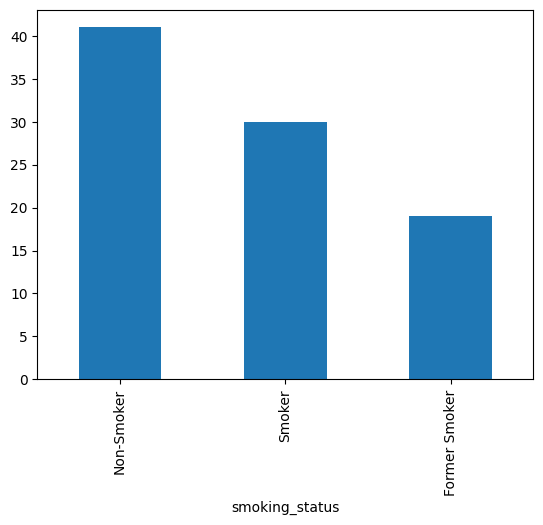

In [5]:
Data_1['smoking_status'].value_counts().plot.bar()

<Axes: xlabel='blood_group'>

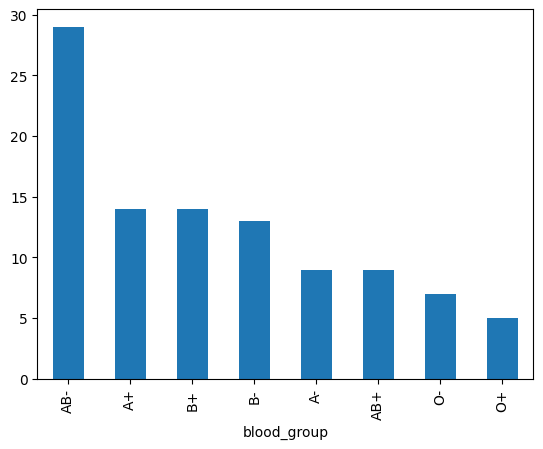

In [37]:
Data_1['blood_group'].value_counts().plot.bar() # after imputation

<Axes: xlabel='region'>

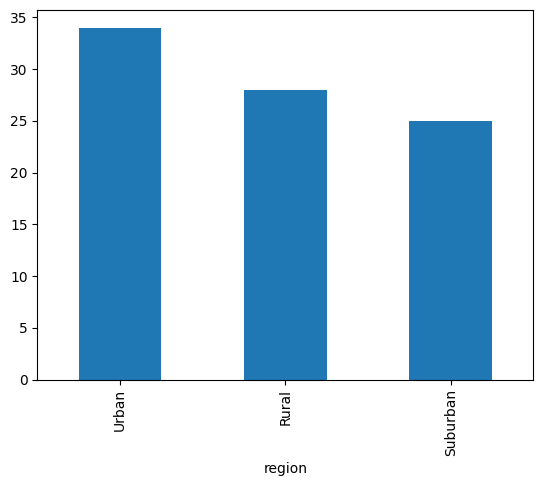

In [38]:
Data_1['region'].value_counts().plot.bar()

In [39]:
Data_1['region'].mode()

0    Urban
Name: region, dtype: str

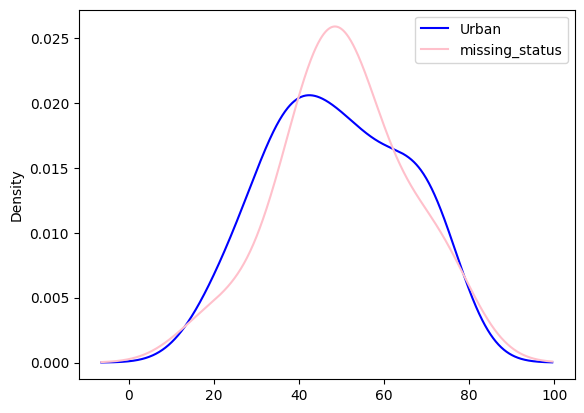

In [40]:
fig = plt.figure()
ax = fig.add_subplot(111)

Data_1[Data_1['region']=='Urban']['age'].plot(kind='kde', ax=ax, color='blue')
Data_1[Data_1['region'].isnull()]['age'].plot(kind='kde', ax=ax, color='pink')

lines, labels = ax.get_legend_handles_labels()
labels =['Urban', 'missing_status']
ax.legend(lines, labels, loc='best')

In [41]:
temp = Data_1[Data_1['region'] == 'Urban']

In [42]:
Data_1['region'] = Data_1['region'].fillna('Urban')

In [43]:
Data_1['region'].isnull().sum()

np.int64(0)

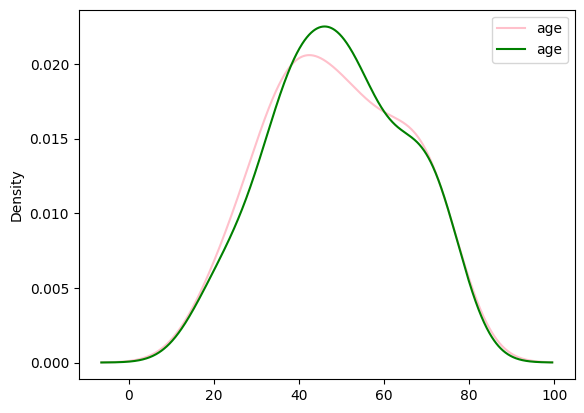

In [47]:
fig = plt.figure()
ax = fig.add_subplot(111)

temp.plot(kind = 'kde', ax = ax, color = 'pink')
Data_1[Data_1['region'] == 'Urban']['age'].plot(kind = 'kde', ax = ax, color = 'green')


lines, labels = ax.get_legend_handles_labels()
legends = ['O', 'I']

ax.legend(lines, labels, loc='best')

In [27]:
Data_1['blood_group'].mode()

0    AB-
Name: blood_group, dtype: str

In [28]:
Data_1['blood_group'].isnull().sum()    # 0 means the fill already ran

np.int64(13)

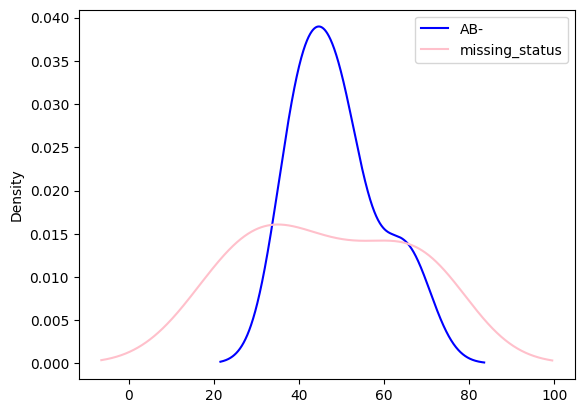

In [29]:
fig = plt.figure()
ax = fig.add_subplot(111)

Data_1[Data_1['blood_group']=='AB-']['age'].plot(kind='kde', ax=ax, color='blue')
Data_1[Data_1['blood_group'].isnull()]['age'].plot(kind='kde', ax=ax, color='pink')

lines, labels = ax.get_legend_handles_labels()
labels =['AB-', 'missing_status']
ax.legend(lines, labels, loc='best')

In [30]:
temp = Data_1[Data_1['blood_group'] == 'AB-']

In [32]:
Data_1['blood_group'] = Data_1['blood_group'].fillna('AB-')


In [33]:
Data_1['blood_group'].isnull().sum()

np.int64(0)

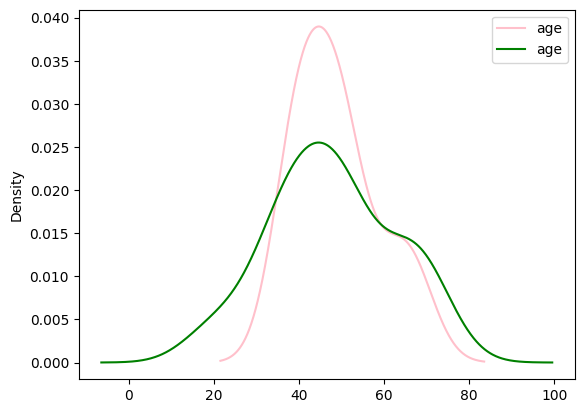

In [35]:
fig = plt.figure()
ax = fig.add_subplot(111)

temp.plot(kind = 'kde', ax = ax, color = 'pink')
Data_1[Data_1['blood_group'] == 'AB-'].plot(kind = 'kde', ax = ax, color = 'green')


lines, labels = ax.get_legend_handles_labels()
legends = ['O', 'I']

ax.legend(lines, labels, loc='best')

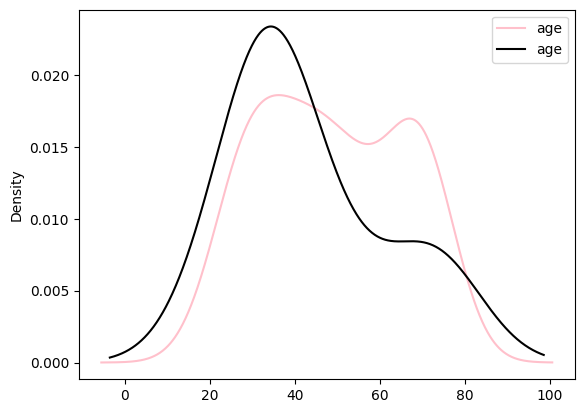

In [21]:
fig = plt.figure()
ax = fig.add_subplot(111)

Data_1[Data_1['diet_type'] == 'Non-Vegetarian'].plot(kind = 'kde', ax = ax, color = 'pink')
Data_1[Data_1['diet_type'].isnull()].plot(kind = 'kde', ax = ax, color = 'black')

lines, labels = ax.get_legend_handles_labels()
legends = ['non-vege', 'missing']

ax.legend(lines, labels, loc='best')